# Exploratory data analysis

# Day 3 - Explore delay propagation and establish baselines

This notebook analyzes linked Southwest (WN) aircraft-flight pairs from January-April 2026. The target is whether the current flight departs at least 15 minutes late (`DEP_DEL15`). It explores delay patterns by hour, weekday, origin airport, previous-flight arrival delay, and scheduled turnaround slack, then compares a majority-class baseline with an initial logistic-regression model.

**Evaluation design:** January-February are used for the initial baseline, January for candidate fitting, and February for model/threshold selection. March is a previously inspected comparison. The selected model is then refit on January-March and evaluated on April as the fresh final holdout. All imputing, scaling, and encoding are fitted on training data only.

**Interpretation limit:** this is an initial historical benchmark, not an operational dispatch recommendation. The available sample covers four months and one carrier.


In [1]:

from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Find the workspace root from the notebook working directory.
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").is_dir():
    raise FileNotFoundError("Open this notebook from the flight project folder.")
PAIR_PATH = ROOT / "data" / "processed" / "wn_aircraft_pairs_2026-01_to_2026-04.csv"
REPORT_DIR = ROOT / "reports" / "metrics"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)



## 1. Load the linked-pair data and inspect the target

Each row represents a current flight and the immediately preceding flight assigned to the same aircraft. The pair construction rules and raw-data quality profile are documented in the Day 2 notebook. Current-flight actual delay is used to create the target, but will not be included among the predictors.


In [2]:

if not PAIR_PATH.is_file():
    raise FileNotFoundError(f"Run notebooks/02_data_preprocessing.ipynb first; missing {PAIR_PATH}")

pairs = pd.read_csv(PAIR_PATH, low_memory=False, parse_dates=["FLIGHT_DATE"])
required = {
    "FLIGHT_DATE", "DEP_DEL15", "DEP_DELAY_MIN", "PREV_ARR_DELAY_MIN",
    "SCHEDULED_TURNAROUND_SLACK_MIN", "ORIGIN", "DEST",
    "DEPARTURE_HOUR_LOCAL", "DAY_OF_WEEK", "MONTH",
}
missing = sorted(required - set(pairs.columns))
if missing:
    raise ValueError(f"Pair file is missing required fields: {missing}")
pairs["FLIGHT_DATE"] = pd.to_datetime(pairs["FLIGHT_DATE"], errors="coerce")
pairs = pairs.dropna(subset=["FLIGHT_DATE", "DEP_DEL15"]).copy()
pairs["DEP_DEL15"] = pairs["DEP_DEL15"].astype(int)

print("Pair table shape:", pairs.shape)
print("Date range:", pairs["FLIGHT_DATE"].min().date(), "to", pairs["FLIGHT_DATE"].max().date())
print("Target counts:")
print(pairs["DEP_DEL15"].value_counts().rename(index={0: "under 15 min", 1: "15+ min"}))
print("Overall 15+ minute departure-delay rate:", round(pairs["DEP_DEL15"].mean(), 4))
print("Missing values in candidate fields:")
print(pairs[list(required)].isna().sum().sort_values(ascending=False).to_string())


Pair table shape: (423660, 22)
Date range: 2026-01-01 to 2026-04-30
Target counts:
DEP_DEL15
under 15 min    321558
15+ min         102102
Name: count, dtype: int64
Overall 15+ minute departure-delay rate: 0.241
Missing values in candidate fields:
DEP_DELAY_MIN                     0
SCHEDULED_TURNAROUND_SLACK_MIN    0
DEP_DEL15                         0
PREV_ARR_DELAY_MIN                0
DAY_OF_WEEK                       0
FLIGHT_DATE                       0
ORIGIN                            0
MONTH                             0
DEST                              0
DEPARTURE_HOUR_LOCAL              0



## 2. Inspect delay distributions

The distribution plots use observed delay values for descriptive analysis. These current-flight outcome values are not model inputs. The display range is capped so the main body of the distribution remains legible; the quantile table preserves tail information for review.


                                   count       mean         std   min    1%    5%   25%   50%   75%    95%    99%     max
PREV_ARR_DELAY_MIN              423660.0   10.96150   27.540544   0.0   0.0   0.0   0.0   0.0  10.0   57.0  134.0   709.0
DEP_DELAY_MIN                   423660.0    9.94049   27.071647 -25.0 -12.0  -9.0  -4.0   0.0  14.0   57.0  125.0   663.0
SCHEDULED_TURNAROUND_SLACK_MIN  423660.0  145.99928  216.327889   0.0  25.0  35.0  40.0  45.0  70.0  630.0  895.0  1440.0


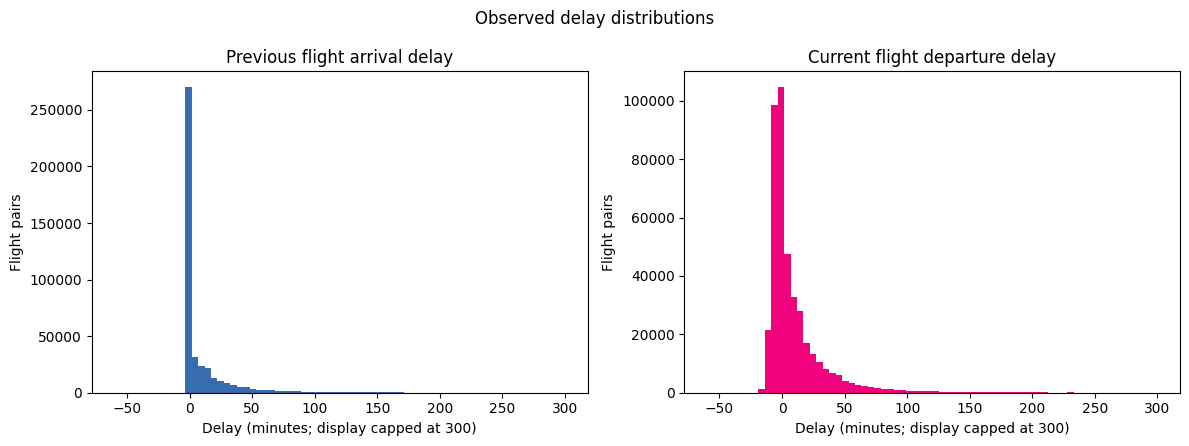

In [3]:

quantile_columns = ["PREV_ARR_DELAY_MIN", "DEP_DELAY_MIN", "SCHEDULED_TURNAROUND_SLACK_MIN"]
quantiles = pairs[quantile_columns].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
quantiles.to_csv(REPORT_DIR / "day3_delay_quantiles.csv")
print(quantiles.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(pairs["PREV_ARR_DELAY_MIN"].dropna(), bins=70, range=(-60, 300), color="#386cb0")
axes[0].set(title="Previous flight arrival delay", xlabel="Delay (minutes; display capped at 300)", ylabel="Flight pairs")
axes[1].hist(pairs["DEP_DELAY_MIN"].dropna(), bins=70, range=(-60, 300), color="#f0027f")
axes[1].set(title="Current flight departure delay", xlabel="Delay (minutes; display capped at 300)", ylabel="Flight pairs")
fig.suptitle("Observed delay distributions")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "delay_distributions.png", dpi=160, bbox_inches="tight")
plt.show()



## 3. Compare delay rates by scheduled operating context

The next summaries show associations in this sample. They are descriptive and do not establish that the hour, weekday, or airport caused a delay. Airport rates are restricted to origins with at least 500 linked pairs to reduce noise from very small samples.


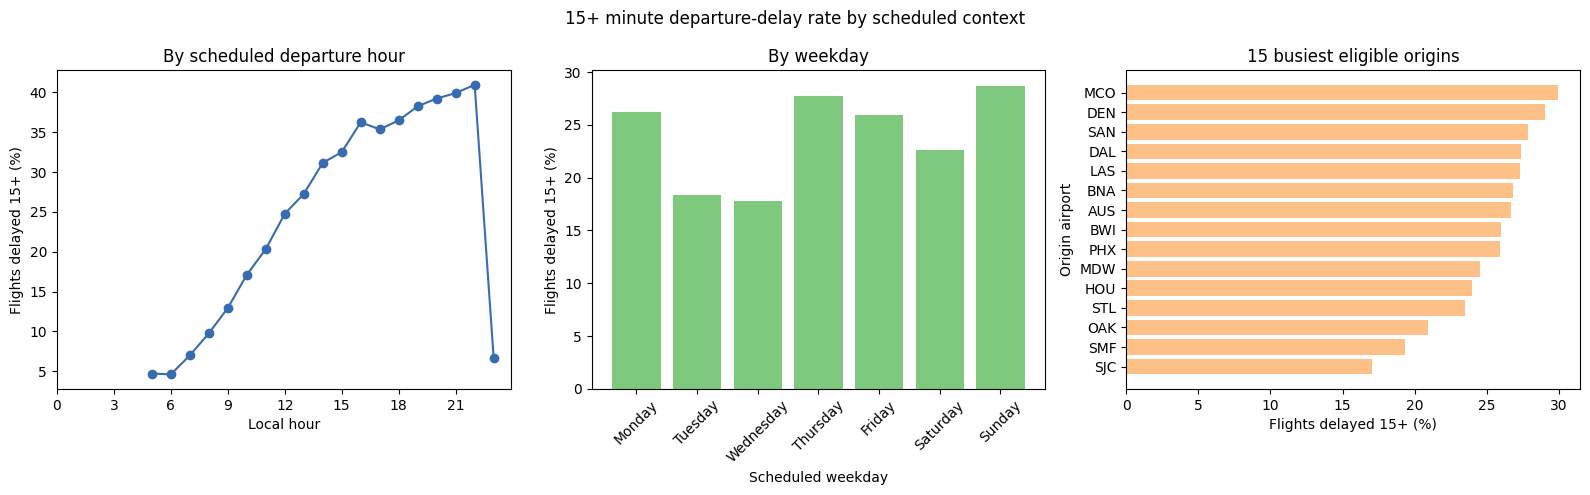

In [4]:

weekday_names = {0:"Monday", 1:"Tuesday", 2:"Wednesday", 3:"Thursday", 4:"Friday", 5:"Saturday", 6:"Sunday"}
by_hour = pairs.groupby("DEPARTURE_HOUR_LOCAL").agg(FLIGHTS=("DEP_DEL15", "size"), DELAY_RATE=("DEP_DEL15", "mean")).reset_index()
by_day = pairs.groupby("DAY_OF_WEEK").agg(FLIGHTS=("DEP_DEL15", "size"), DELAY_RATE=("DEP_DEL15", "mean")).reset_index()
by_day["DAY_NAME"] = by_day["DAY_OF_WEEK"].map(weekday_names)
by_origin = pairs.groupby("ORIGIN").agg(FLIGHTS=("DEP_DEL15", "size"), DELAY_RATE=("DEP_DEL15", "mean")).reset_index()
by_origin = by_origin.loc[by_origin["FLIGHTS"] >= 500].nlargest(15, "FLIGHTS").sort_values("DELAY_RATE")
by_hour.to_csv(REPORT_DIR / "day3_delay_rate_by_hour.csv", index=False)
by_day.to_csv(REPORT_DIR / "day3_delay_rate_by_weekday.csv", index=False)
by_origin.to_csv(REPORT_DIR / "day3_delay_rate_by_origin.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(by_hour["DEPARTURE_HOUR_LOCAL"], by_hour["DELAY_RATE"] * 100, marker="o", color="#386cb0")
axes[0].set(title="By scheduled departure hour", xlabel="Local hour", ylabel="Flights delayed 15+ (%)", xticks=range(0,24,3))
axes[1].bar(by_day["DAY_NAME"], by_day["DELAY_RATE"] * 100, color="#7fc97f")
axes[1].set(title="By weekday", xlabel="Scheduled weekday", ylabel="Flights delayed 15+ (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[2].barh(by_origin["ORIGIN"], by_origin["DELAY_RATE"] * 100, color="#fdc086")
axes[2].set(title="15 busiest eligible origins", xlabel="Flights delayed 15+ (%)", ylabel="Origin airport")
fig.suptitle("15+ minute departure-delay rate by scheduled context")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "delay_rates_by_schedule_and_origin.png", dpi=160, bbox_inches="tight")
plt.show()



## 4. Measure propagation patterns and turnaround slack

Previous-flight arrival delay is known once the inbound aircraft arrives; scheduled turnaround slack is the time between the previous scheduled arrival and the current scheduled departure. Buckets are used only for readable plots and summaries. The model below uses the continuous values, avoiding information loss from binning.


Next-flight delay by previous-flight arrival-delay band:
PREV_ARR_DELAY_BAND  FLIGHT_PAIRS  NEXT_DELAY_RATE  MEAN_NEXT_DELAY_MIN
                <=0        263027         0.091242             1.856159
               1-15         78367         0.321577            10.912897
              16-30         35197         0.602608            20.422792
              31-60         27443         0.687680            32.441424
             61-120         14119         0.659678            53.245202
               >120          5507         0.636644            92.078627
Next-flight delay by scheduled turnaround-slack band:
SCHEDULED_SLACK_BAND  FLIGHT_PAIRS  NEXT_DELAY_RATE  MEAN_NEXT_DELAY_MIN
                0-15          2605         0.843378            40.279463
               16-30          5472         0.575841            25.302997
               31-60        296271         0.283085            12.112195
               61-90         27243         0.182983             6.811144
              91-120

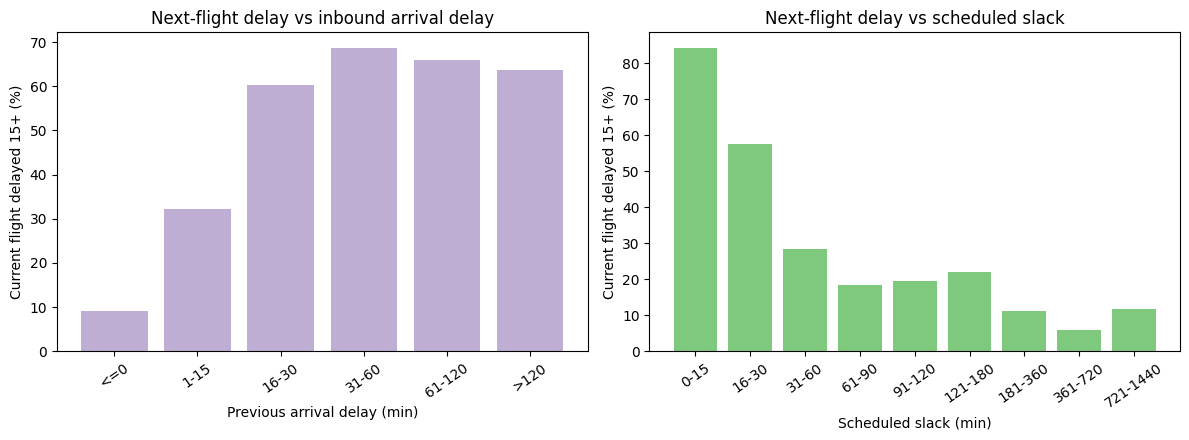

In [5]:

pairs["PREV_ARR_DELAY_BAND"] = pd.cut(
    pairs["PREV_ARR_DELAY_MIN"],
    bins=[-np.inf, 0, 15, 30, 60, 120, np.inf],
    labels=["<=0", "1-15", "16-30", "31-60", "61-120", ">120"],
    include_lowest=True,
)
pairs["SCHEDULED_SLACK_BAND"] = pd.cut(
    pairs["SCHEDULED_TURNAROUND_SLACK_MIN"],
    bins=[0, 15, 30, 60, 90, 120, 180, 360, 720, 1440],
    labels=["0-15", "16-30", "31-60", "61-90", "91-120", "121-180", "181-360", "361-720", "721-1440"],
    include_lowest=True,
)
by_inbound = pairs.groupby("PREV_ARR_DELAY_BAND", observed=False).agg(FLIGHT_PAIRS=("DEP_DEL15", "size"), NEXT_DELAY_RATE=("DEP_DEL15", "mean"), MEAN_NEXT_DELAY_MIN=("DEP_DELAY_MIN", "mean")).reset_index()
by_slack = pairs.groupby("SCHEDULED_SLACK_BAND", observed=False).agg(FLIGHT_PAIRS=("DEP_DEL15", "size"), NEXT_DELAY_RATE=("DEP_DEL15", "mean"), MEAN_NEXT_DELAY_MIN=("DEP_DELAY_MIN", "mean")).reset_index()
by_inbound.to_csv(REPORT_DIR / "day3_propagation_by_inbound_delay.csv", index=False)
by_slack.to_csv(REPORT_DIR / "day3_propagation_by_scheduled_slack.csv", index=False)
print("Next-flight delay by previous-flight arrival-delay band:")
print(by_inbound.to_string(index=False))
print("Next-flight delay by scheduled turnaround-slack band:")
print(by_slack.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(by_inbound["PREV_ARR_DELAY_BAND"].astype(str), by_inbound["NEXT_DELAY_RATE"] * 100, color="#beaed4")
axes[0].set(title="Next-flight delay vs inbound arrival delay", xlabel="Previous arrival delay (min)", ylabel="Current flight delayed 15+ (%)")
axes[0].tick_params(axis="x", rotation=35)
axes[1].bar(by_slack["SCHEDULED_SLACK_BAND"].astype(str), by_slack["NEXT_DELAY_RATE"] * 100, color="#7fc97f")
axes[1].set(title="Next-flight delay vs scheduled slack", xlabel="Scheduled slack (min)", ylabel="Current flight delayed 15+ (%)")
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "propagation_by_inbound_delay_and_slack.png", dpi=160, bbox_inches="tight")
plt.show()
